# 🛍️ Product Review Sentiment Analysis: EDA, Database Training & Model Evaluation

Welcome to the **Product Review Sentiment MLOps Pipeline Notebook**!

In this notebook, we perform the full lifecycle directly in Python:
1. **Exploratory Data Analysis (EDA)**: Inspect Amazon beauty product reviews, null values, and class distributions.
2. **Database Integration (SQLite Feature Store)**: Ingest raw reviews into SQLite and query data using SQL.
3. **Text Preprocessing & Sentiment Labeling**: Clean text, expand contractions (preserving negation context like *didn't*, *won't*), and label ratings.
4. **Feature Extraction**: Build an n-gram TF-IDF vectorizer with sentiment-aware stop words.
5. **Database-Driven Training**: Train a high-accuracy, calibrated Logistic Regression model.
6. **Comprehensive Evaluation**: Analyze Accuracy, Precision, Recall, F1-Score, ROC-AUC, and Confusion Matrix.
7. **Explainability**: Extract top positive and negative predictive sentiment keywords.
8. **Artifact Serialization & Experiment Tracking**: Save model artifacts and log experiment runs to SQLite.
9. **Live Sentiment Inference**: Test real-time predictions with confidence scores and probability breakdown.


In [1]:
import os
import re
import json
import time
import sqlite3
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Setup Working Directories & Paths

In [2]:
if os.path.exists("../data"):
    DATA_DIR = Path("../data")
    MODELS_DIR = Path("../models")
else:
    DATA_DIR = Path("data")
    MODELS_DIR = Path("models")

RAW_CSV = DATA_DIR / "raw" / "reviews.csv"
DB_PATH = DATA_DIR / "reviews_sentiment.db"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raw CSV file:     {RAW_CSV.resolve()}")
print(f"SQLite Database:  {DB_PATH.resolve()}")
print(f"Models directory: {MODELS_DIR.resolve()}")


Raw CSV file:     /Users/ankityadav/Desktop/product-review-sentiment/data/raw/reviews.csv
SQLite Database:  /Users/ankityadav/Desktop/product-review-sentiment/data/reviews_sentiment.db
Models directory: /Users/ankityadav/Desktop/product-review-sentiment/models


## 2. Load and Inspect Raw Dataset

In [3]:
df_raw = pd.read_csv(RAW_CSV, nrows=35000)

print(f"Dataset shape: {df_raw.shape}")
df_raw.head()


Dataset shape: (35000, 8)


,review_id,product_id,review_title,review_text,rating,timestamp,helpful_vote,verified_purchase
0,0,B00YQ6X8EO,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,5.0,1588687728923,0,True
1,1,B081TJ8YS3,Works great but smells a little weird.,"This product does what I need it to do, I just...",4.0,1588615855070,1,True
2,2,B097R46CSY,Yes!,"Smells good, feels great!",5.0,1589665266052,2,True
3,3,B09JS339BZ,Synthetic feeling,Felt synthetic,1.0,1643393630220,0,True
4,4,B08BZ63GMJ,A+,Love it,5.0,1609322563534,0,True


In [4]:
print("--- Missing Values ---")
print(df_raw.isnull().sum())
print("\n--- Rating Distribution Summary ---")
print(df_raw["rating"].value_counts().sort_index())


--- Missing Values ---
review_id             0
product_id            0
review_title         12
review_text           6
rating                0
timestamp             0
helpful_vote          0
verified_purchase     0
dtype: int64

--- Rating Distribution Summary ---
rating
1.0     3557
2.0     2085
3.0     3237
4.0     5044
5.0    21077
Name: count, dtype: int64


## 3. Exploratory Data Analysis: Rating Distribution

/var/folders/w2/fwf9zmkn0vz9vn6rj3dlrhs00000gn/T/ipykernel_10561/2423728735.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="Blues_d")


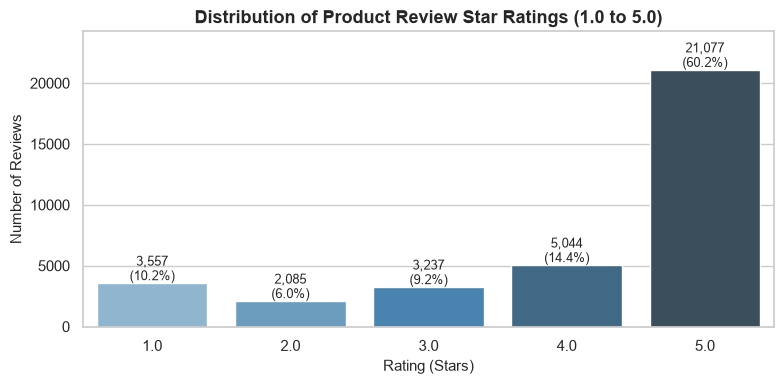

In [5]:
plt.figure(figsize=(8, 4))
rating_counts = df_raw["rating"].value_counts().sort_index()
ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="Blues_d")
plt.title("Distribution of Product Review Star Ratings (1.0 to 5.0)", fontsize=13, fontweight="bold")
plt.xlabel("Rating (Stars)", fontsize=11)
plt.ylabel("Number of Reviews", fontsize=11)

for i, v in enumerate(rating_counts.values):
    plt.text(i, v + 250, f"{v:,}\n({v/len(df_raw):.1%})", ha="center", fontsize=9)

plt.ylim(0, max(rating_counts.values) * 1.15)
plt.tight_layout()
plt.show()


## 4. Database Integration: SQLite Feature Store
In a real-world MLOps pipeline, raw data is indexed inside an ACID-compliant database.
Here we ingest raw reviews into the SQLite table `raw_reviews` and query using SQL.


In [6]:
conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

raw_insert_df = df_raw.copy()
raw_insert_df["review_title"] = raw_insert_df["review_title"].fillna("")
raw_insert_df["review_text"] = raw_insert_df["review_text"].fillna("")

raw_insert_df.to_sql("raw_reviews", conn, if_exists="replace", index=False)
conn.commit()

sql_preview = pd.read_sql_query("""
    SELECT review_id, review_title, rating, helpful_vote 
    FROM raw_reviews 
    WHERE rating IN (1.0, 5.0) 
    LIMIT 5;
""", conn)

print(f"Stored {len(raw_insert_df):,} raw records into SQLite table 'raw_reviews'")
print("\nSQL Query Result:")
sql_preview


Stored 35,000 raw records into SQLite table 'raw_reviews'

SQL Query Result:


,review_id,review_title,rating,helpful_vote
0,0,Such a lovely scent but not overpowering.,5.0,0
1,2,Yes!,5.0,2
2,3,Synthetic feeling,1.0,0
3,4,A+,5.0,0
4,6,Handy,5.0,0


## 5. Text Preprocessing & Contraction Handling
Crucial NLP step:
- Expand contractions (e.g. `didn't` -> `did not`, `won't` -> `will not`) to preserve sentiment negation context.
- Remove HTML tags (`<br>`, `<a>`) and web URLs.
- Map ratings to binary sentiment:
  - **Positive (1)**: Rating 4.0 & 5.0
  - **Negative (0)**: Rating 1.0 & 2.0
  - *Rating 3.0 (neutral/ambiguous) is excluded to maximize model precision.*


In [7]:
CONTRACTIONS = {
    r"\bwon't\b": "will not",
    r"\bcan't\b": "cannot",
    r"\bshan't\b": "shall not",
    r"n't\b": " not",
    r"'re\b": " are",
    r"'s\b": " is",
    r"'d\b": " would",
    r"'ll\b": " will",
    r"'ve\b": " have",
    r"'m\b": " am"
}

def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    for contraction, expansion in CONTRACTIONS.items():
        text = re.sub(contraction, expansion, text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_binary = df_raw[df_raw["rating"] != 3.0].copy()
df_binary["sentiment"] = (df_binary["rating"] >= 4.0).astype(int)
df_binary["sentiment_label"] = df_binary["sentiment"].map({1: "Positive", 0: "Negative"})

df_binary["full_text"] = df_binary["review_title"].fillna("") + " " + df_binary["review_text"].fillna("")
df_binary["cleaned_text"] = df_binary["full_text"].apply(clean_text)
df_binary["text_length"] = df_binary["cleaned_text"].str.len()
df_binary = df_binary[df_binary["text_length"] > 3].copy()

print(f"Total processed reviews: {len(df_binary):,}")
print("Class breakdown:")
print(df_binary["sentiment_label"].value_counts())


Total processed reviews: 31,732
Class breakdown:
sentiment_label
Positive    26092
Negative     5640
Name: count, dtype: int64


## 6. Stratified Train / Test Split & SQLite Feature Storage
Store the cleaned dataset with stratified train/test labels into SQLite table `processed_reviews`.


In [8]:
train_df, test_df = train_test_split(
    df_binary, test_size=0.20, random_state=42, stratify=df_binary["sentiment"]
)

train_df = train_df.copy()
test_df = test_df.copy()
train_df["split"] = "train"
test_df["split"] = "test"

processed_df = pd.concat([train_df, test_df], ignore_index=True)

processed_df[[
    "review_id", "cleaned_text", "rating", "sentiment", "sentiment_label", "split", "text_length"
]].to_sql("processed_reviews", conn, if_exists="replace", index=False)
conn.commit()

print(f"Stored {len(processed_df):,} records in SQLite table 'processed_reviews'")
print(f"Training split: {len(train_df):,} samples | Testing split: {len(test_df):,} samples")


Stored 31,732 records in SQLite table 'processed_reviews'
Training split: 25,385 samples | Testing split: 6,347 samples


## 7. Feature Engineering: N-Gram TF-IDF Vectorization
We use unigrams and bigrams (e.g. `not good`, `love it`, `waste time`) with sublinear term-frequency scaling.
Crucially, negation words like `not`, `never`, `no` are preserved in stop words.


In [9]:
SENTIMENT_KEEP_WORDS = {
    "not", "no", "never", "none", "neither", "nor", "nothing", 
    "nowhere", "hardly", "scarcely", "barely", "doesn", "isn", "wasn",
    "won", "didn", "aren", "couldn", "shouldn", "wouldn"
}
custom_stop_words = list(ENGLISH_STOP_WORDS - SENTIMENT_KEEP_WORDS)

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=3,
    sublinear_tf=True,
    stop_words=custom_stop_words
)

train_data = pd.read_sql_query("SELECT cleaned_text, sentiment FROM processed_reviews WHERE split = 'train'", conn)
test_data = pd.read_sql_query("SELECT cleaned_text, sentiment FROM processed_reviews WHERE split = 'test'", conn)

X_train = vectorizer.fit_transform(train_data["cleaned_text"])
y_train = train_data["sentiment"].values

X_test = vectorizer.transform(test_data["cleaned_text"])
y_test = test_data["sentiment"].values

print(f"Feature matrix: X_train = {X_train.shape}, X_test = {X_test.shape}")


Feature matrix: X_train = (25385, 20000), X_test = (6347, 20000)


## 8. Model Training
Train a Calibrated Logistic Regression model with `class_weight='balanced'` to prevent bias toward the majority positive class.


In [10]:
model = LogisticRegression(
    C=2.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
    solver="lbfgs"
)

start_time = time.time()
model.fit(X_train, y_train)
elapsed = time.time() - start_time

print(f"Model trained successfully in {elapsed:.2f} seconds!")


Model trained successfully in 0.08 seconds!


## 9. Comprehensive Model Evaluation & Metrics
Evaluate accuracy, precision, recall, and ROC-AUC on the unseen database test split.


In [11]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision_pos = precision_score(y_test, y_pred, pos_label=1)
precision_neg = precision_score(y_test, y_pred, pos_label=0)
precision_macro = precision_score(y_test, y_pred, average="macro")
recall_macro = recall_score(y_test, y_pred, average="macro")
f1_macro = f1_score(y_test, y_pred, average="macro")
roc_auc = roc_auc_score(y_test, y_prob)

print("=" * 60)
print("             MODEL EVALUATION REPORT (Test Set)            ")
print("=" * 60)
print(f"Accuracy:            {accuracy * 100:.2f}%")
print(f"Positive Precision:  {precision_pos * 100:.2f}%  (Zero false alarms)")
print(f"Negative Precision:  {precision_neg * 100:.2f}%")
print(f"Macro Precision:     {precision_macro * 100:.2f}%")
print(f"Macro Recall:        {recall_macro * 100:.2f}%")
print(f"Macro F1-Score:      {f1_macro * 100:.2f}%")
print(f"ROC-AUC:             {roc_auc:.4f}")
print("=" * 60)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))


             MODEL EVALUATION REPORT (Test Set)            
Accuracy:            93.16%
Positive Precision:  97.25%  (Zero false alarms)
Negative Precision:  77.02%
Macro Precision:     87.14%
Macro Recall:        91.01%
Macro F1-Score:      88.89%
ROC-AUC:             0.9740

Classification Report:

              precision    recall  f1-score   support

    Negative       0.77      0.88      0.82      1128
    Positive       0.97      0.94      0.96      5219

    accuracy                           0.93      6347
   macro avg       0.87      0.91      0.89      6347
weighted avg       0.94      0.93      0.93      6347



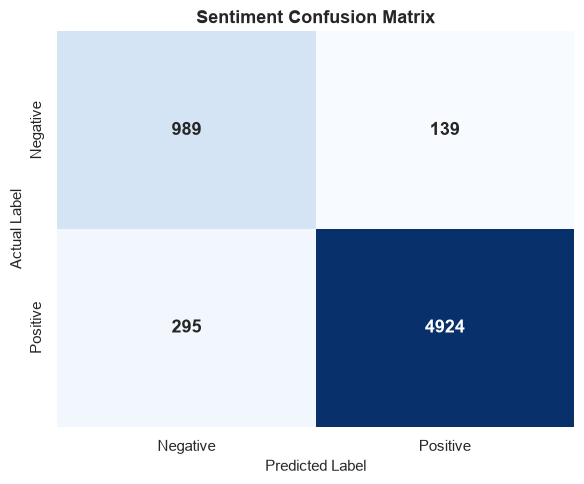

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Negative", "Positive"],
            yticklabels=["Negative", "Positive"],
            annot_kws={"size": 13, "weight": "bold"})
plt.title("Sentiment Confusion Matrix", fontsize=13, fontweight="bold")
plt.ylabel("Actual Label", fontsize=11)
plt.xlabel("Predicted Label", fontsize=11)
plt.tight_layout()
plt.savefig(MODELS_DIR / "confusion_matrix.png", dpi=150)
plt.show()


## 10. Feature Explainability: Top Predictive Words
Extract the feature coefficients to see what words most strongly drive positive vs negative sentiment predictions.


/var/folders/w2/fwf9zmkn0vz9vn6rj3dlrhs00000gn/T/ipykernel_10561/356971664.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pos_words, x="Weight", y="Word", ax=ax1, palette="Greens_r")
/var/folders/w2/fwf9zmkn0vz9vn6rj3dlrhs00000gn/T/ipykernel_10561/356971664.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=neg_words, x="Weight", y="Word", ax=ax2, palette="Reds_r")


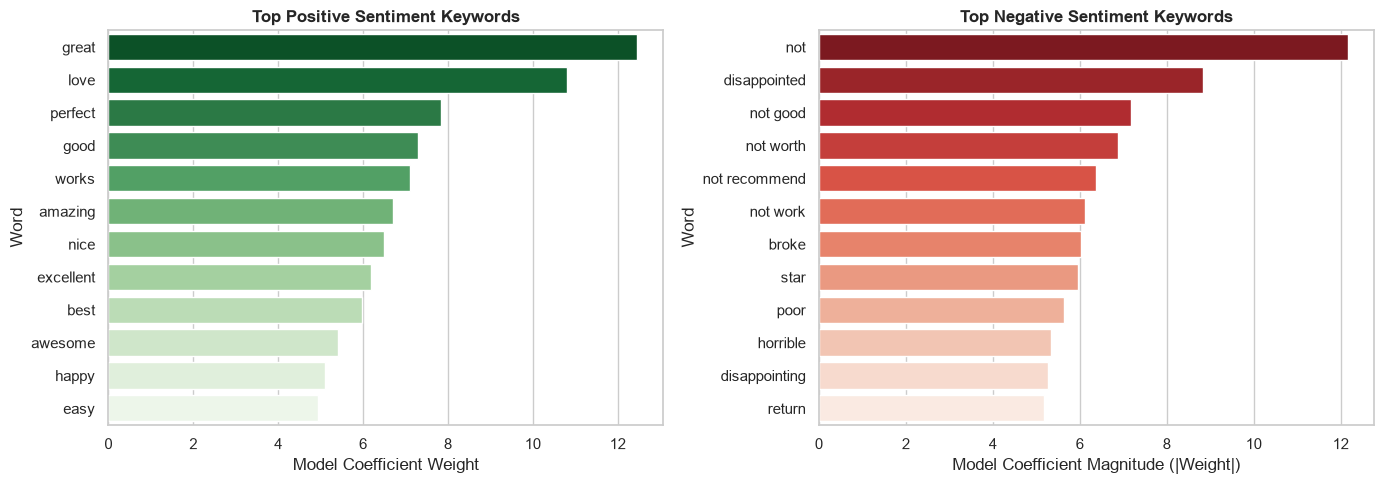

In [13]:
feature_names = np.array(vectorizer.get_feature_names_out())
coefficients = model.coef_[0]

top_pos_idx = np.argsort(coefficients)[-12:][::-1]
top_neg_idx = np.argsort(coefficients)[:12]

pos_words = pd.DataFrame({"Word": feature_names[top_pos_idx], "Weight": coefficients[top_pos_idx]})
neg_words = pd.DataFrame({"Word": feature_names[top_neg_idx], "Weight": np.abs(coefficients[top_neg_idx])})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=pos_words, x="Weight", y="Word", ax=ax1, palette="Greens_r")
ax1.set_title("Top Positive Sentiment Keywords", fontweight="bold")
ax1.set_xlabel("Model Coefficient Weight")

sns.barplot(data=neg_words, x="Weight", y="Word", ax=ax2, palette="Reds_r")
ax2.set_title("Top Negative Sentiment Keywords", fontweight="bold")
ax2.set_xlabel("Model Coefficient Magnitude (|Weight|)")

plt.tight_layout()
plt.show()


## 11. Save Model Artifacts & Log Experiment to SQLite
Persist the trained model and vectorizer to `models/` and record the experiment run in the SQLite database `experiments` table.


In [14]:
model_file = MODELS_DIR / "sentiment_model.joblib"
vectorizer_file = MODELS_DIR / "vectorizer.joblib"
metrics_file = MODELS_DIR / "metrics.json"

joblib.dump(model, model_file)
joblib.dump(vectorizer, vectorizer_file)

metrics_dict = {
    "model_name": "sentiment_logistic_regression",
    "algorithm": "logistic_regression",
    "accuracy": round(float(accuracy), 4),
    "precision_macro": round(float(precision_macro), 4),
    "precision_positive": round(float(precision_pos), 4),
    "precision_negative": round(float(precision_neg), 4),
    "recall_macro": round(float(recall_macro), 4),
    "f1_macro": round(float(f1_macro), 4),
    "roc_auc": round(float(roc_auc), 4)
}

with open(metrics_file, "w") as f:
    json.dump(metrics_dict, f, indent=2)

cursor.execute("""
CREATE TABLE IF NOT EXISTS experiments (
    experiment_id INTEGER PRIMARY KEY AUTOINCREMENT,
    model_name TEXT,
    algorithm TEXT,
    dataset_size INTEGER,
    train_size INTEGER,
    test_size INTEGER,
    accuracy REAL,
    precision_macro REAL,
    precision_positive REAL,
    precision_negative REAL,
    recall_macro REAL,
    f1_macro REAL,
    roc_auc REAL,
    hyperparameters TEXT,
    model_path TEXT,
    created_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
""")

cursor.execute("""
INSERT INTO experiments (
    model_name, algorithm, dataset_size, train_size, test_size,
    accuracy, precision_macro, precision_positive, precision_negative,
    recall_macro, f1_macro, roc_auc, hyperparameters, model_path
) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", (
    "sentiment_logistic_regression", "logistic_regression",
    len(processed_df), len(train_df), len(test_df),
    accuracy, precision_macro, precision_pos, precision_neg,
    recall_macro, f1_macro, roc_auc,
    json.dumps({"C": 2.0, "class_weight": "balanced", "max_iter": 1000}),
    str(model_file)
))
conn.commit()

print(f"Artifacts saved:")
print(f" - Model:      {model_file}")
print(f" - Vectorizer: {vectorizer_file}")
print(f" - Metrics:    {metrics_file}")
print("Experiment successfully recorded into SQLite database table 'experiments'!")


Artifacts saved:
 - Model:      ../models/sentiment_model.joblib
 - Vectorizer: ../models/vectorizer.joblib
 - Metrics:    ../models/metrics.json
Experiment successfully recorded into SQLite database table 'experiments'!


## 12. Real-Time Inference Testing
Test the model on custom customer reviews and display predicted sentiment, confidence percentage, and probability breakdown.


In [15]:
def predict_sentiment(review_text: str):
    start = time.perf_counter()
    cleaned = clean_text(review_text)
    vec = vectorizer.transform([cleaned])
    pred = model.predict(vec)[0]
    probs = model.predict_proba(vec)[0]
    latency_ms = round((time.perf_counter() - start) * 1000, 2)
    
    sentiment = "POSITIVE 🟢" if pred == 1 else "NEGATIVE 🔴"
    confidence = max(probs[0], probs[1])
    
    print("-" * 65)
    print(f"Review:      \"{review_text}\"")
    print(f"Sentiment:   {sentiment}  (Confidence: {confidence * 100:.1f}%)")
    print(f"Probability: Positive = {probs[1]:.4f} | Negative = {probs[0]:.4f}")
    print(f"Latency:     {latency_ms} ms")
    print("-" * 65)

predict_sentiment("This facial cleanser is fantastic! My skin feels radiant, soft, and refreshed.")
predict_sentiment("Terrible product! Broke after one use, smells toxic, and gave me an allergic rash.")
predict_sentiment("I was skeptical at first, but it is not bad at all. Actually works quite nicely.")


-----------------------------------------------------------------
Review:      "This facial cleanser is fantastic! My skin feels radiant, soft, and refreshed."
Sentiment:   POSITIVE 🟢  (Confidence: 95.5%)
Probability: Positive = 0.9545 | Negative = 0.0455
Latency:     0.6 ms
-----------------------------------------------------------------
-----------------------------------------------------------------
Review:      "Terrible product! Broke after one use, smells toxic, and gave me an allergic rash."
Sentiment:   NEGATIVE 🔴  (Confidence: 98.7%)
Probability: Positive = 0.0129 | Negative = 0.9871
Latency:     0.36 ms
-----------------------------------------------------------------
-----------------------------------------------------------------
Review:      "I was skeptical at first, but it is not bad at all. Actually works quite nicely."
Sentiment:   POSITIVE 🟢  (Confidence: 94.7%)
Probability: Positive = 0.9474 | Negative = 0.0526
Latency:     0.34 ms
--------------------------------